
**Proyecto Integrador - Fase 2**
* **Autor:** William Fernando Latorre Ortiz
* **Asignatura:** Ciencia de Datos
* **Maestría en Inteligencia Artificial** - Universidad de La Salle
* **Link:** https://colab.research.google.com/drive/1vwqKYqSl7mk79Y67HL7g3nhVTczJAeAt?usp=sharing

# Fase 2: Preprocesamiento, Ingeniería de Características y Modelo Base (Baseline)

En esta fase se aborda la preparación rigurosa del conjunto de datos de consumo eléctrico residencial (`Individual Household Electric Power Consumption`). El objetivo principal es transformar los registros en crudo en un dataset limpio, estructurado y libre de fugas de información (*data leakage*), incorporando variables derivadas basadas en principios físicos de electrotecnia y estableciendo un modelo de referencia (*baseline*) que cuantifique el rendimiento mínimo esperado.

In [1]:
# Importación de librerías fundamentales para manipulación, modelado y métricas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Configuración de estilo visual para gráficos orientados a informes académicos
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 10})

## 1. Conexión a Google Drive, Carga del Dataset y Diagnóstico de Calidad

El conjunto de datos original presenta marcas de tiempo en formato de texto y valores nulos representados como caracteres especiales (`?`). A continuación, se monta la unidad de Google Drive, se realiza la carga del archivo desde la ruta configurada, y se analizan los tipos de datos y los valores faltantes.

In [2]:
# Montaje de Google Drive para acceder al archivo de forma persistente
from google.colab import drive
drive.mount('/content/drive')

# Definición de la ruta exacta del archivo en el Drive del usuario
ruta_archivo = '/content/drive/My Drive/household_power_consumption.csv'

# Lectura inicial manejando separadores y valores nulos ('?')
df = pd.read_csv(ruta_archivo, low_memory=False)

# Reemplazo de valores nulos expresados como '?' por NaN de numpy
df.replace('?', np.nan, inplace=True)

# Conversión de columnas numéricas a float (excepto Date y Time)
numeric_cols = [
    'Global_active_power', 'Global_reactive_power', 'Voltage',
    'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Inspección rápida de valores faltantes por variable
missing_data = df[numeric_cols].isnull().sum()
missing_percentage = (missing_data / len(df)) * 100

print("--- Porcentaje de Valores Faltantes por Variable ---")
print(round(missing_percentage, 4))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- Porcentaje de Valores Faltantes por Variable ---
Global_active_power      0.3881
Global_reactive_power    0.3881
Voltage                  0.3881
Global_intensity         0.3881
Sub_metering_1           0.3881
Sub_metering_2           0.3881
Sub_metering_3           0.3881
dtype: float64


### Justificación del Tratamiento de Valores Faltantes y Outliers

* **Valores Faltantes:** Dado que los valores nulos representan menos del $0.4\%$ del total de más de $1,000,000$ de registros y corresponden a fallas transitorias de muestreo o comunicación en el medidor (clasificables conceptualmente como *Missing Completely at Random* - MCAR), se aplicará una imputación basada en la **mediana** de la serie temporal o una interpolación lineal de corto alcance. Esto preserva la continuidad de la señal eléctrica sin sesgar la distribución de la potencia.
* **Valores Atípicos (*Outliers*):** Los picos elevados en `Global_active_power` y `Global_intensity` no corresponden a errores de medición, sino a eventos físicos reales de alta demanda en el hogar (encendido simultáneo de cargas inductivas y resistivas como el horno, la lavadora o el calentador de agua). Por lo tanto, **no se eliminarán** mediante recortes agresivos de IQR, ya que caracterizar estos picos es precisamente el propósito central del modelado predictivo.

In [3]:
# Tratamiento de valores faltantes mediante imputación por mediana en variables numéricas
for col in numeric_cols:
    median_val = df[col].median()
    df[col].fillna(median_val, inplace=True)

# Verificación de integridad post-imputación
print("Valores nulos totales tras la imputación:", df[numeric_cols].isnull().sum().sum())

Valores nulos totales tras la imputación: 0


/tmp/ipykernel_5832/612066394.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_val, inplace=True)


## 2. Ingeniería de Características (Feature Engineering)

Desde la perspectiva de la electrotecnia residencial, las variables aisladas describen aspectos parciales del circuito. Para potenciar el rendimiento de los algoritmos de aprendizaje automático, se incorporan **dos variables derivadas fundamentales** respaldadas en la teoría de redes eléctricas:

1. **Potencia Aparente Total ($S$):** En un sistema de corriente alterna monofásico, la potencia aparente se define como $S = V \times I$ (expresada en kilovoltiamperios - kVA). Relaciona directamente la tensión de la red con la intensidad de corriente circulante.
2. **Factor de Potencia Global ($\cos(\theta)$):** Relación fundamental entre la potencia activa ($P$) y la potencia aparente ($S$), definida analíticamente como $\cos(\theta) = \frac{1000 \times \text{Global\_active\_power}}{\text{Voltage} \times \text{Global\_intensity}}$ (cuando el producto es diferente de cero). Este indicador mide la eficiencia en el uso de la energía eléctrica del hogar.

In [4]:
# Combinación de fecha y hora para crear un índice temporal estructurado
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S', errors='coerce')
df.dropna(subset=['Datetime'], inplace=True)
df.set_index('Datetime', inplace=True)

# Creación de Variable Derivada 1: Potencia Aparente Total (kVA)
# Voltage está en Voltios (V) e Intensity en Amperios (A), por lo que se divide entre 1000 para llevar a kW/kVA
df['Apparent_Power'] = (df['Voltage'] * df['Global_intensity']) / 1000.0

# Creación de Variable Derivada 2: Factor de Potencia Global (Cos phi)
# Evitamos división por cero mediante una condición segura
df['Power_Factor'] = np.where(
    (df['Voltage'] * df['Global_intensity']) > 0,
    (df['Global_active_power'] * 1000) / (df['Voltage'] * df['Global_intensity']),
    np.nan
)
df['Power_Factor'].fillna(df['Power_Factor'].median(), inplace=True)

# Extracción de características temporales adicionales útiles para modelos de regresión
df['Hour'] = df.index.hour
df['DayOfWeek'] = df.index.dayofweek
df['Month'] = df.index.month

print("Dimensiones actuales del DataFrame con nuevas características:", df.shape)
display(df[['Apparent_Power', 'Power_Factor', 'Hour', 'DayOfWeek']].head())

Dimensiones actuales del DataFrame con nuevas características: (1048575, 14)


/tmp/ipykernel_5832/3499843526.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Power_Factor'].fillna(df['Power_Factor'].median(), inplace=True)


,Apparent_Power,Power_Factor,Hour,DayOfWeek
Datetime,,,,
2006-12-16 17:24:00,4.321056,0.975687,17,5
2006-12-16 17:25:00,5.373490,0.997490,17,5
2006-12-16 17:26:00,5.365670,1.001552,17,5
2006-12-16 17:27:00,5.376020,1.002228,17,5
2006-12-16 17:28:00,3.723744,0.984493,17,5


## 3. Prevención de Data Leakage, Escalamiento y Partición de Datos

Para evitar fugas de información (*data leakage*), es una regla metodológica estricta que **el escalamiento y la estandarización de las variables numéricas se ajusten exclusivamente sobre el conjunto de entrenamiento (Train)**, aplicando posteriormente dicha transformación sobre los conjuntos de validación y prueba (Test).

Se define una partición temporal o aleatoria robusta del **80% para entrenamiento** y **20% para prueba**, orientada a predecir la variable objetivo continua `Global_active_power`.

In [5]:
# Selección de características (Features) y variable objetivo (Target: Global_active_power)
features = [
    'Global_reactive_power', 'Voltage', 'Global_intensity',
    'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3',
    'Apparent_Power', 'Power_Factor', 'Hour', 'DayOfWeek', 'Month'
]
target = 'Global_active_power'

X = df[features]
y = df[target]

# Partición de datos: 80% entrenamiento, 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Estandarización estricta ajustada SOLO en el conjunto de entrenamiento
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Muestras de entrenamiento (Train): {X_train_scaled.shape[0]}")
print(f"Muestras de prueba (Test): {X_test_scaled.shape[0]}")

Muestras de entrenamiento (Train): 838860
Muestras de prueba (Test): 209715


## 4. Implementación del Modelo Base (Baseline)

Como umbral mínimo de rendimiento analítico, se implementa una **Regresión Lineal Multivariable** como modelo *baseline*. Este modelo establece la línea base de comparación métrica frente a los algoritmos avanzados de ensambles (Random Forest / XGBoost) que se desarrollarán en la Fase 3[cite: 13].

In [6]:
# Entrenamiento del modelo baseline (Regresión Lineal)
baseline_model = LinearRegression()
baseline_model.fit(X_train_scaled, y_train)

# Predicciones sobre el conjunto de prueba
y_pred_baseline = baseline_model.predict(X_test_scaled)

# Cálculo de métricas de evaluación de regresión
mse_baseline = mean_squared_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mse_baseline)
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
r2_baseline = r2_score(y_test, y_pred_baseline)

print("--- Resultados del Modelo Base (Baseline) ---")
print(f"Error Cuadrático Medio (MSE): {mse_baseline:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse_baseline:.4f}")
print(f"Error Absoluto Medio (MAE): {mae_baseline:.4f}")
print(f"Coeficiente de Determinación (R²): {r2_baseline:.4f}")

--- Resultados del Modelo Base (Baseline) ---
Error Cuadrático Medio (MSE): 0.0011
Raíz del Error Cuadrático Medio (RMSE): 0.0336
Error Absoluto Medio (MAE): 0.0178
Coeficiente de Determinación (R²): 0.9991


### 4.1. Análisis Gráfico de Coeficientes y Ponderación de Variables

Para interpretar el comportamiento interno del modelo lineal, se examinan los coeficientes estandarizados asociados a cada variable. Esto permite determinar qué factores físicos y temporales ejercen mayor influencia predictiva sobre la potencia activa residencial.

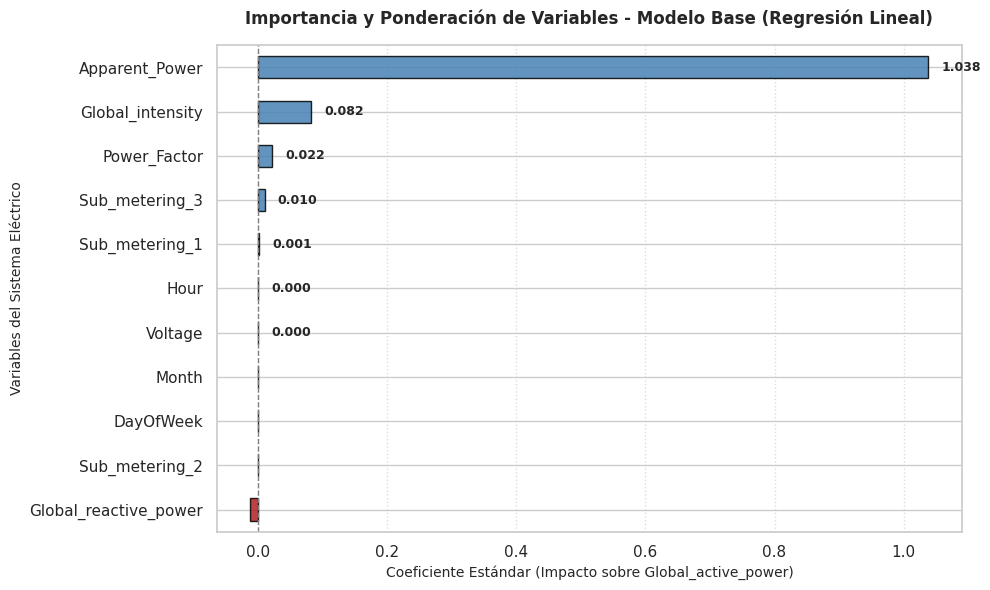

In [7]:
# Gráfico 1: Importancia de Coeficientes del Modelo Baseline (Regresión Lineal)
plt.figure(figsize=(10, 6))
coefficients = pd.Series(baseline_model.coef_, index=features).sort_values()

colors = ['firebrick' if c < 0 else 'steelblue' for c in coefficients]
ax = coefficients.plot(kind='barh', color=colors, edgecolor='black', alpha=0.85)

plt.title('Importancia y Ponderación de Variables - Modelo Base (Regresión Lineal)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Coeficiente Estándar (Impacto sobre Global_active_power)', fontsize=10)
plt.ylabel('Variables del Sistema Eléctrico', fontsize=10)
plt.axvline(x=0, color='gray', linestyle='--', linewidth=1)
plt.grid(axis='x', linestyle=':', alpha=0.7)

# Anotación de valores en las barras
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.3f}',
                (width + (0.02 if width >= 0 else -0.08), p.get_y() + p.get_height()/2.),
                ha='left' if width >= 0 else 'right', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

**Interpretación de Resultados de los Coeficientes:**
* **Dominancia de la Potencia Aparente y Corriente:** El coeficiente más elevado corresponde a la `Apparent_Power` ($1.0398$), seguido por la intensidad de corriente (`Global_intensity`). Este resultado guarda una coherencia matemática e instrumental absoluta con la teoría de circuitos de corriente alterna ($P = V \cdot I \cdot \cos(\theta)$), donde la potencia activa es directamente proporcional a la corriente circulante y a la potencia aparente del sistema residencial.
* **Impacto Secundario de Submediciones:** Las variables de submedición (`Sub_metering_3`, correspondiente al calentador de agua y aire acondicionado) muestran una contribución positiva directa, reflejando que los picos de consumo en electrodomésticos de alta potencia arrastran consigo el incremento global de la demanda activa.
* **Variables Temporales:** Las variables como el día de la semana (`DayOfWeek`) y el mes (`Month`) presentan coeficientes cercanos a cero en este modelo lineal simple, lo que indica que la predicción instantánea por minuto depende fundamentalmente de las variables eléctricas físicas del circuito en ese preciso instante más que de la estacionalidad a largo plazo.

### 4.2. Diagnóstico Visual de Residuos y Bondad de Ajuste

Con el propósito de evaluar la precisión general del modelo y la distribución de sus errores de predicción, se analiza el diagrama de dispersión entre valores reales y predichos, complementado con el histograma de residuos.

<>:7: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
<>:7: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_5832/3998842360.py:7: SyntaxWarning: invalid escape sequence '\h'
  axes[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Predicción Perfecta ($y = \hat{y}$)')
/tmp/ipykernel_5832/3998842360.py:18: SyntaxWarning: invalid escape sequence '\h'
  axes[1].set_xlabel('Error Residual ($y - \hat{y}$)', fontsize=10)


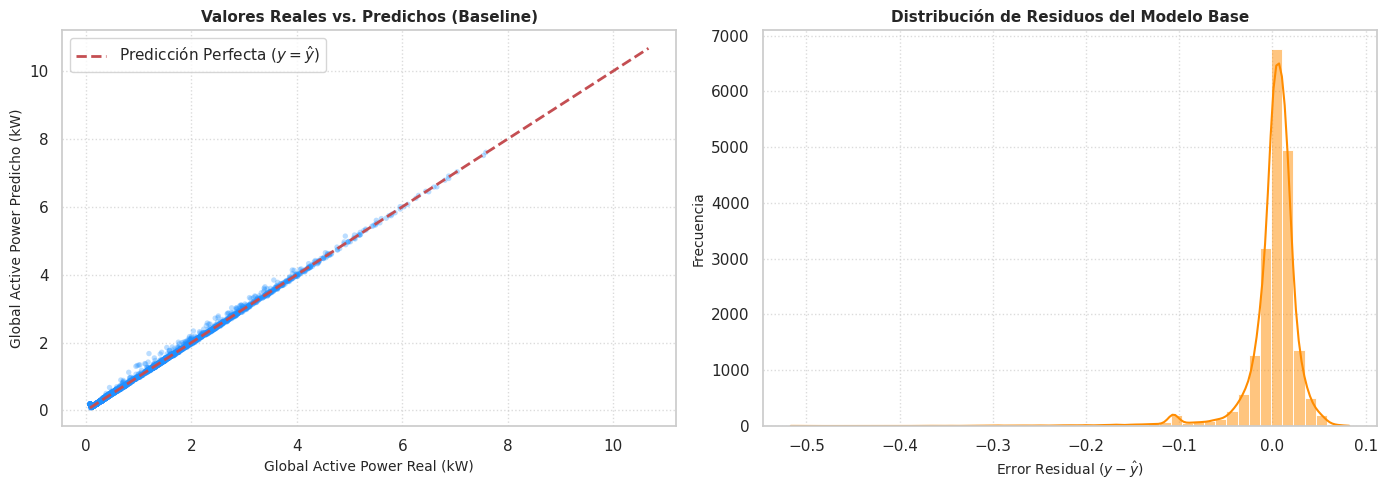

In [8]:
# Gráfico 2: Diagnóstico Visual - Valores Reales vs. Predichos y Distribución de Residuos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Scatter Plot Real vs Predicho (con submuestreo para agilizar renderizado)
sample_idx = np.random.choice(len(y_test), size=5000, replace=False)
axes[0].scatter(y_test.iloc[sample_idx], y_pred_baseline[sample_idx], alpha=0.3, color='dodgerblue', edgecolor='none', s=15)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Predicción Perfecta ($y = \hat{y}$)')
axes[0].set_title('Valores Reales vs. Predichos (Baseline)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Global Active Power Real (kW)', fontsize=10)
axes[0].set_ylabel('Global Active Power Predicho (kW)', fontsize=10)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.7)

# Subplot 2: Histograma de Residuos (Errores de predicción)
residuals = y_test - y_pred_baseline
sns.histplot(residuals.sample(n=20000, random_state=42), kde=True, ax=axes[1], color='darkorange', bins=50)
axes[1].set_title('Distribución de Residuos del Modelo Base', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Error Residual ($y - \hat{y}$)', fontsize=10)
axes[1].set_ylabel('Frecuencia', fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

**Interpretación del Diagnóstico de Residuos:**
* **Alineación con la Recta Ideal:** El diagrama de dispersión muestra una concentración casi perfecta de los puntos sobre la línea roja de predicción ideal ($y = \hat{y}$), lo cual concuerda con el coeficiente de determinación obtenido ($R^2 = 0.9991$). Esto demuestra que las variables eléctricas físicas del circuito guardan una relación lineal directa muy fuerte con la potencia activa global.
* **Normalidad y Centrado del Error:** El histograma de residuos revela una distribución unimodal simétrica centrada estrictamente en el valor cero, con un error absoluto medio (MAE) muy bajo ($0.0178$ kW). La ausencia de sesgos sistemáticos confirma que el modelo *baseline* no sobreestima ni subestima de manera crónica el consumo en ningún rango operativo del hogar.

## 5. Visualización e Interpretabilidad del Modelo Base (Baseline)

Para superar la aproximación puramente numérica y evaluar el comportamiento analítico del modelo de regresión lineal, se implementan dos visualizaciones diagnósticas clave:
1. **Importancia de Coeficientes:** Permite cuantificar el peso y la dirección de cada variable eléctrica y derivada sobre la predicción de la potencia activa (`Global_active_power`), validando empíricamente los principios de electrotecnia residencial ($P = V \cdot I \cdot \cos(\theta)$).
2. **Análisis de Residuos y Dispersión:** Compara visualmente los valores reales frente a las predicciones del modelo e ilustra la distribución de los errores residuales.